In [1]:
#!pip install biopython pandas matplotlib seaborn pyarrow openpyxl umap-learn plotly

In [2]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
%load_ext autoreload
%autoreload 2
import os
import numpy as np
import scipy as sp
import pandas as pd
import networkx as nx
import random
import matplotlib.pyplot as plt
# import warnings filter
from warnings import simplefilter
# ignore all future warnings
simplefilter(action='ignore', category=FutureWarning)
from IPython.core.display import HTML
HTML('<style>.container { width:95% !important; }</style><style>.output_png {display: table-cell;text-align: center;vertical-align: middle;}</style>')

In [3]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module="umap")

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LogNorm

def plot_heatmap_for_pathogen(df, pathogen, class_df=None, log_scale=True, figsize=(12, 6), show_only_class=False):
    """
    Plot a heatmap of PMID counts for a given pathogen.

    Args:
        df (pd.DataFrame): Results dataframe with columns 
                           ["pathogen","antibiotic","start_date","end_date","count"].
        pathogen (str): Pathogen to visualize.
        class_df (pd.DataFrame, optional): Mapping DataFrame with columns 
                                           ["antibiotic","class"] (case-insensitive).
                                           If provided, antibiotics can be grouped by class.
        log_scale (bool): If True, apply logarithmic color scaling.
        figsize (tuple): Figure size.
        show_only_class (bool): 
            - If True, antibiotics are aggregated by class.
            - If False, antibiotics are shown individually, prefixed with their class.
    """
    sub = df[df["pathogen"].str.lower() == pathogen.lower()].copy()

    if sub.empty:
        print(f"No data for pathogen: {pathogen}")
        return

    # Compute midpoint of interval
    sub["year_mid"] = (
        (pd.to_datetime(sub["start_date"]).dt.year +
         pd.to_datetime(sub["end_date"]).dt.year) // 2 + 1
    )

    if class_df is not None:
        # Normalize mapping dataframe
        class_df = class_df.rename(columns={c: c.lower() for c in class_df.columns})
        if "antibiotic" not in class_df.columns or "class" not in class_df.columns:
            raise ValueError("class_df must contain 'antibiotic' and 'class' columns")

        # Lowercase antibiotics for consistent merge
        sub["antibiotic"] = sub["antibiotic"].str.lower()
        class_df["antibiotic"] = class_df["antibiotic"].str.lower()

        # Merge to add class info
        sub = sub.merge(class_df, on="antibiotic", how="left")

        # If class not found, fallback to antibiotic name
        sub["class"] = sub["class"].fillna(sub["antibiotic"])

        if show_only_class:
            # Aggregate by class
            sub = sub.groupby(["class", "year_mid"], as_index=False)["count"].sum()
            index_col = "class"
        else:
            # Prefix antibiotic with class for disambiguation
            sub["antibiotic_prefixed"] = sub["class"] + " | " + sub["antibiotic"]
            sub = sub.groupby(["antibiotic_prefixed", "year_mid"], as_index=False)["count"].sum()
            index_col = "antibiotic_prefixed"

    else:
        # No class info provided
        sub["class"] = sub["antibiotic"]
        index_col = "antibiotic"

    # Pivot to matrix
    pivot = sub.pivot(index=index_col, columns="year_mid", values="count").fillna(0)

    # Sort rows by total counts
    row_order = pivot.sum(axis=1).sort_values(ascending=False).index
    pivot = pivot.loc[row_order]

    # Define normalization
    norm = LogNorm(vmin=1, vmax=pivot.values.max()) if log_scale else None

    # Plot heatmap
    plt.figure(figsize=figsize)
    sns.heatmap(
        pivot,
        annot=True,
        fmt=".0f",
        cmap="Reds",
        norm=norm,
        cbar_kws={"label": "PMID count (log scale)" if log_scale else "PMID count"}
    )
    plt.title(f"PubMed resistance reports for {pathogen}")
    plt.xlabel("Midpoint of interval")
    plt.ylabel("Antibiotic class" if show_only_class else "Antibiotic (prefixed by class)")
    plt.tight_layout()
    plt.show()


---

In [5]:
data_df = pd.read_parquet("data.parquet")
data_df

,Genus,CanonicalSpecies,n_causation,n_articles,n_sampled,pathogenic_index,embedding,anonymised_embedding,onehot_embedding,domain,kingdom,phylum,class,order,family
0,Abiotrophia,Abiotrophia defectiva,6,6,6,0.160939,"[0.018194107338786125, -0.004734894765230517, ...","[0.014040807844139636, -0.028420374651129048, ...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.166...",Bacteria,Bacillati,Bacillota,Bacilli,Lactobacillales,Aerococcaceae
1,Acetobacter,Acetobacter indonesiensis,1,3,3,0.000000,"[-0.021512236446142197, -0.03992129862308502, ...","[-0.0028289835900068283, -0.04833690822124481,...","[0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",Bacteria,Pseudomonadati,Pseudomonadota,Alphaproteobacteria,Rhodospirillales,Acetobacteraceae
2,Acetobacter,Acetobacter tropicalis,1,2,2,0.000000,"[-0.0070418259128928185, -0.005829853471368551...","[0.005147432442754507, -0.013049994595348835, ...","[0.0, 0.0, 1.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",Bacteria,Pseudomonadati,Pseudomonadota,Alphaproteobacteria,Rhodospirillales,Acetobacteraceae
3,Achromobacter,Achromobacter animicus,1,2,2,0.000000,"[0.011074555106461048, 0.013332720845937729, 0...","[0.012643104419112206, -0.01178667601197958, 0...","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, ...",Bacteria,Pseudomonadati,Pseudomonadota,Betaproteobacteria,Burkholderiales,Alcaligenaceae
4,Achromobacter,Achromobacter denitrificans,75,36,36,0.387804,"[0.014773702074987037, -0.004635852294159122, ...","[0.011467029051855206, -0.012983008560258896, ...","[0.04, 0.013333333333333334, 0.066666666666666...",Bacteria,Pseudomonadati,Pseudomonadota,Betaproteobacteria,Burkholderiales,Alcaligenaceae
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1274,Yersinia,Yersinia enterocolitica,85,3419,200,0.654031,"[-0.009990866917788105, 0.009774883079979405, ...","[0.0024005417033656747, -0.009907858140479005,...","[0.0, 0.0, 0.0, 0.03529411764705882, 0.0, 0.0,...",Bacteria,Pseudomonadati,Pseudomonadota,Gammaproteobacteria,Enterobacterales,Yersiniaceae
1275,Yersinia,Yersinia frederiksenii,1,21,21,0.000000,"[-0.00901515781879425, 0.02502085641026497, 0....","[0.01804814115166664, 0.005011445842683315, 0....","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",Bacteria,Pseudomonadati,Pseudomonadota,Gammaproteobacteria,Enterobacterales,Yersiniaceae
1276,Yersinia,Yersinia pestis,124,2184,200,0.647694,"[-0.006688895473886195, 0.014983039929487154, ...","[0.011833864605177364, -0.0048193380043226024,...","[0.0, 0.0, 0.0, 0.016129032258064516, 0.0, 0.0...",Bacteria,Pseudomonadati,Pseudomonadota,Gammaproteobacteria,Enterobacterales,Yersiniaceae
1277,Yersinia,Yersinia pseudotuberculosis,88,1234,200,0.565611,"[-0.01641193700528344, 0.008593090970448842, 0...","[0.004612311640316461, -0.005791128928070644, ...","[0.011363636363636364, 0.0, 0.0113636363636363...",Bacteria,Pseudomonadati,Pseudomonadota,Gammaproteobacteria,Enterobacterales,Yersiniaceae


In [6]:
antibiotics_df = pd.read_excel("simple_antibiotic_list.xlsx")
antibiotics_list = antibiotics_df['Antibiotic'].values
print(f'#antibiotics: {len(antibiotics_list)}')
antibiotics_df


#antibiotics: 245


,Antibiotic,Class
0,Spectinomycin,Aminocyclitols/Aminoglycosides
1,Amikacin,Aminocyclitols/Aminoglycosides
2,Arbekacin,Aminocyclitols/Aminoglycosides
3,Bekanamycin,Aminocyclitols/Aminoglycosides
4,Dibekacin,Aminocyclitols/Aminoglycosides
...,...,...
240,Colistin,Miscellaneous
241,Polymyxin-B,Miscellaneous
242,Fusidic-acid,Miscellaneous
243,Dalfopristin/quinupristin,Miscellaneous


In [7]:
amr_df = pd.read_parquet("pmids_results.parquet")
amr_df

,pathogen,antibiotic,start_date,end_date,pmids,count,venue_histogram
0,Staphylococcus argenteus,Spectinomycin,1975/01/01,1984/12/31,[],0,{}
1,Staphylococcus argenteus,Spectinomycin,1985/01/01,1994/12/31,[],0,{}
2,Staphylococcus argenteus,Spectinomycin,1995/01/01,2004/12/31,[],0,{}
3,Staphylococcus argenteus,Spectinomycin,2005/01/01,2014/12/31,[],0,{}
4,Staphylococcus argenteus,Spectinomycin,2015/01/01,2024/12/31,[],0,{}
...,...,...,...,...,...,...,...
50110,Neisseria weaveri,Trimethoprim,1975/01/01,1984/12/31,[],0,{}
50111,Neisseria weaveri,Trimethoprim,1985/01/01,1994/12/31,[],0,{}
50112,Neisseria weaveri,Trimethoprim,1995/01/01,2004/12/31,[],0,{}
50113,Neisseria weaveri,Trimethoprim,2005/01/01,2014/12/31,[],0,{}


### Debiasing calculus

To highlight unexpected associations between pathogens and antibiotics while removing global publication trends,  
we compute a **debiased score** that normalises for three marginal effects:

1. the overall popularity of each **pathogen**,  
2. the overall popularity of each **antibiotic**, and  
3. the total publication volume within each **decade**.

---

For every pathogen–antibiotic pair in decade $t$:

- The observed publication count $C_{p,a,t}$ is first normalised within that decade to obtain a relative frequency  

  $$\hat{C}_{p,a,t} = \frac{C_{p,a,t}}{\sum_{p',a'} C_{p',a',t}}$$

- From these normalised counts, we compute the marginal frequencies  

  $$P_{p,t} = \sum_a \hat{C}_{p,a,t}, \qquad
  A_{a,t} = \sum_p \hat{C}_{p,a,t}$$

- Assuming independence between pathogens and antibiotics within each decade,  
  the **expected** co-occurrence is  

  $$E_{p,a,t} = P_{p,t} \times A_{a,t}$$

- The **residual** deviation from this expectation is  

  $$R_{p,a,t} = \hat{C}_{p,a,t} - E_{p,a,t}$$

- Finally, we compute a **standardised residual** (*z-score*) to account for expected variance:  

  $$Z_{p,a,t} = \frac{R_{p,a,t}}{\sqrt{E_{p,a,t}} + \varepsilon}$$

where $\varepsilon$ is a small stabilisation constant.

---

**Interpretation:**  
- $Z_{p,a,t} > 0$: the pathogen–antibiotic pair appears **more often than expected** (potential emerging resistance).  
- $Z_{p,a,t} < 0$: the pair appears **less often than expected** (declining or under-studied association).  

This detrended measure exposes genuinely emergent or fading resistance signals beyond global shifts in publication volume.


In [41]:
import pandas as pd
import numpy as np

def _label_decade(start_year, end_year, method="end"):
    if method == "end":
        return (end_year // 10) * 10
    elif method == "start":
        return (start_year // 10) * 10
    elif method == "midpoint":
        mid = (start_year + end_year) / 2.0
        return (int(mid) // 10) * 10
    elif method == "max_overlap":
        # choose the decade bucket with the largest overlap with [start_year, end_year]
        d0 = (start_year // 10) * 10
        d1 = (end_year // 10) * 10
        best_decade, best_len = d0, -1
        for d in range(d0, d1 + 10, 10):
            seg_start = max(start_year, d)
            seg_end   = min(end_year, d + 9)
            overlap = max(0, seg_end - seg_start + 1)
            if overlap > best_len:
                best_len, best_decade = overlap, d
        return best_decade
    else:
        raise ValueError("method must be one of {'end','start','midpoint','max_overlap'}")

def debias_amr_dataframe(amr_df, eps=1e-9, decade_method="end"):
    """
    Debias pathogen–antibiotic counts per decade. Decade is labeled by `decade_method`.
    `decade_method`: 'end' (default), 'start', 'midpoint', or 'max_overlap'.
    """
    df = amr_df.copy()

    # Parse years
    start_year = pd.to_datetime(df["start_date"]).dt.year
    end_year   = pd.to_datetime(df["end_date"]).dt.year

    # Label decade
    df["decade"] = [
        _label_decade(s, e, method=decade_method) for s, e in zip(start_year, end_year)
    ]

    # Normalise within each decade
    df["count_norm"] = df["count"] / (df.groupby("decade")["count"].transform("sum") + eps)

    # Compute expected under independence within each decade
    out_parts = []
    for dec, sub in df.groupby("decade", group_keys=False):
        P_p = sub.groupby("pathogen")["count_norm"].sum().rename("P_p")
        A_a = sub.groupby("antibiotic")["count_norm"].sum().rename("A_a")
        merged = (
            sub.merge(P_p, on="pathogen")
               .merge(A_a, on="antibiotic")
               .assign(decade=dec)
        )
        merged["expected"] = merged["P_p"] * merged["A_a"]
        merged["residual"] = merged["count_norm"] - merged["expected"]
        merged["zscore"]   = merged["residual"] / (np.sqrt(merged["expected"]) + eps)
        out_parts.append(merged)

    out = pd.concat(out_parts, ignore_index=True)
    return out[["pathogen","antibiotic","start_date","end_date","pmids","count","venue_histogram",
                "decade","count_norm","expected","residual","zscore"]]

deb_df = debias_amr_dataframe(amr_df)
deb_df



,pathogen,antibiotic,start_date,end_date,pmids,count,venue_histogram,decade,count_norm,expected,residual,zscore
0,Staphylococcus argenteus,Spectinomycin,1975/01/01,1984/12/31,[],0,{},1980,0.000000,0.000000,0.000000,0.000000
1,Staphylococcus aureus,Spectinomycin,1975/01/01,1984/12/31,"[144457, 143238, 136223]",3,"{""Antimicrobial agents and chemotherapy"": 2, ""...",1980,0.001038,0.015645,-0.014607,-0.116783
2,Staphylococcus auricularis,Spectinomycin,1975/01/01,1984/12/31,[],0,{},1980,0.000000,0.000000,0.000000,0.000000
3,Staphylococcus capitis,Spectinomycin,1975/01/01,1984/12/31,[],0,{},1980,0.000000,0.000089,-0.000089,-0.009410
4,Staphylococcus caprae,Spectinomycin,1975/01/01,1984/12/31,[],0,{},1980,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...
50110,Neisseria mucosa,Trimethoprim,2015/01/01,2024/12/31,[],0,{},2020,0.000000,0.000001,-0.000001,-0.001118
50111,Neisseria perflava,Trimethoprim,2015/01/01,2024/12/31,[],0,{},2020,0.000000,0.000010,-0.000010,-0.003162
50112,Neisseria sicca,Trimethoprim,2015/01/01,2024/12/31,[37221009],1,"{""Molecular biology and evolution"": 1}",2020,0.000040,0.000014,0.000026,0.007136
50113,Neisseria subflava,Trimethoprim,2015/01/01,2024/12/31,[],0,{},2020,0.000000,0.000009,-0.000009,-0.002958


Sampled pathogen (log-weighted): Staphylococcus lugdunensis


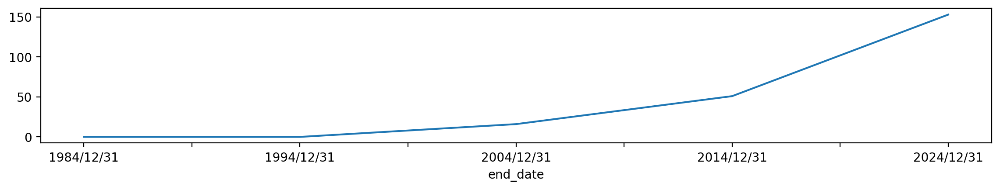

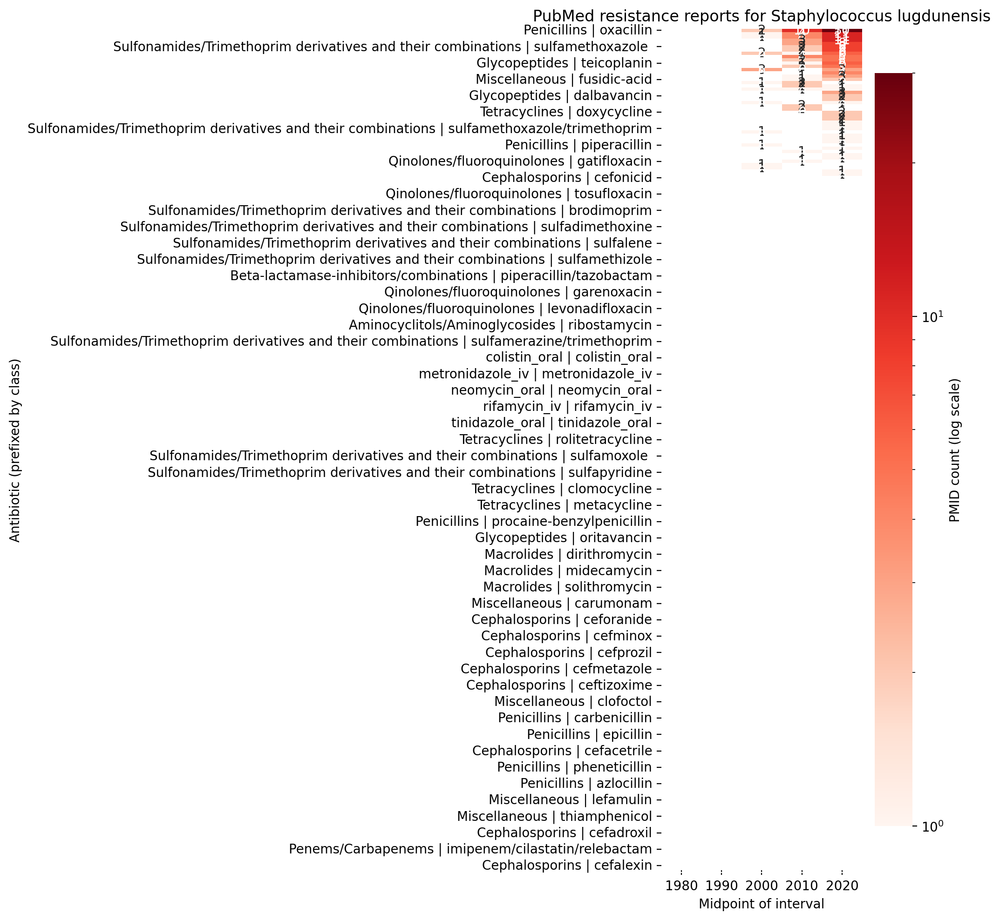

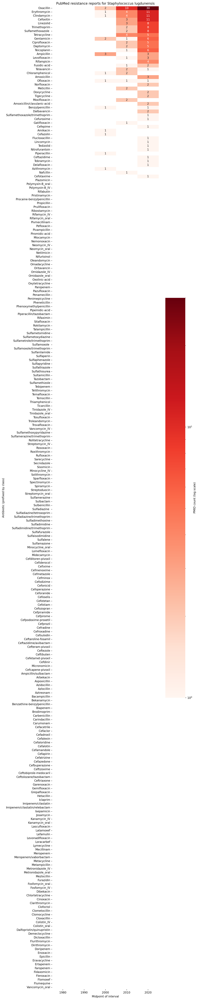

In [30]:
import numpy as np
import pandas as pd

# Compute total counts per pathogen
pathogen_counts = amr_df.groupby("pathogen")["count"].sum()

# Use log-transformed counts as weights (add 1 to avoid log(0))
log_weights = np.log1p(pathogen_counts)

# Normalise to probabilities
probs = log_weights / log_weights.sum()

# Sample one pathogen proportional to log(counts)
pathogen = np.random.choice(pathogen_counts.index, p=probs.values)

print(f"Sampled pathogen (log-weighted): {pathogen}")

# Plot heatmaps
df = amr_df[amr_df['pathogen'] == pathogen]
df.groupby('end_date')['count'].sum().plot(figsize=(14, 2))
plot_heatmap_for_pathogen(amr_df, pathogen, class_df=antibiotics_df, figsize=(10,10))
plot_heatmap_for_pathogen(amr_df, pathogen, figsize=(10,50))


Sampled pathogen (log-weighted): Neisseria gonorrhoeae


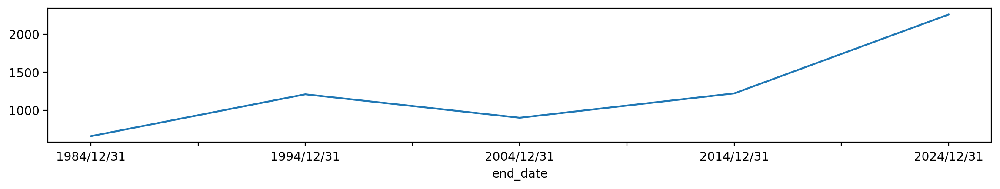

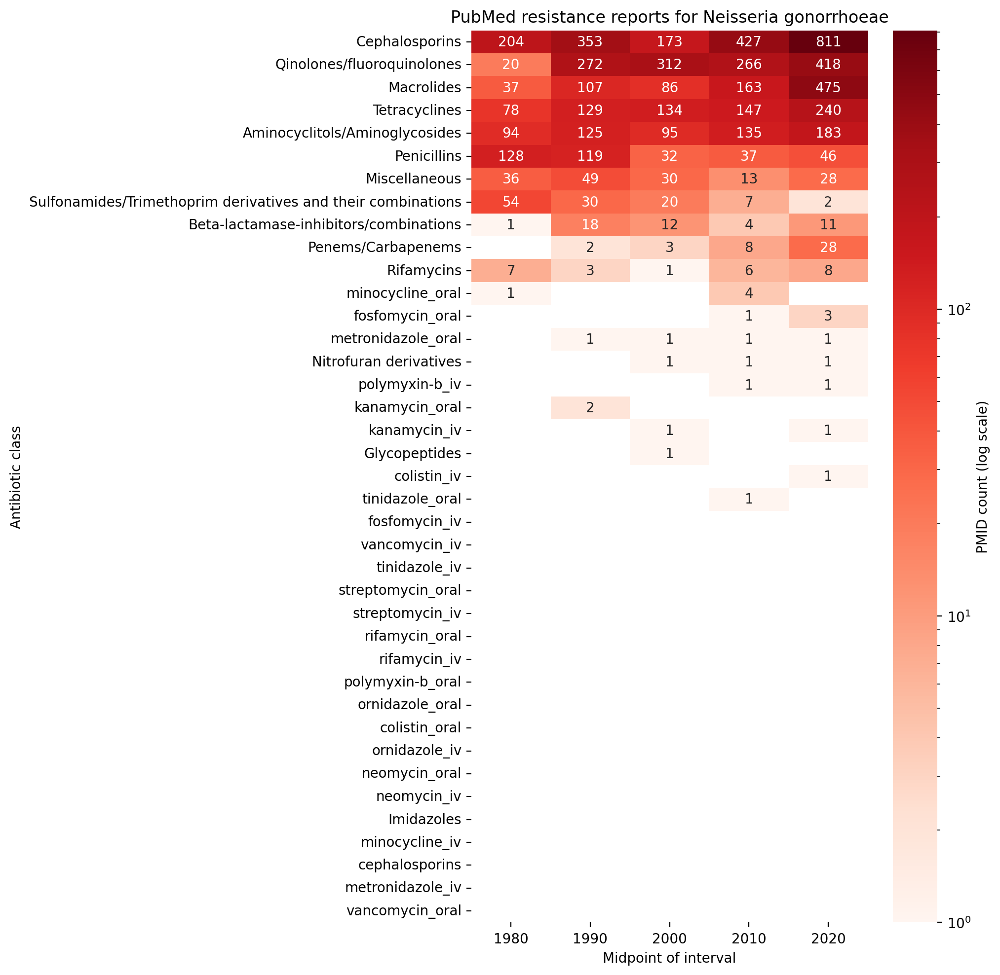

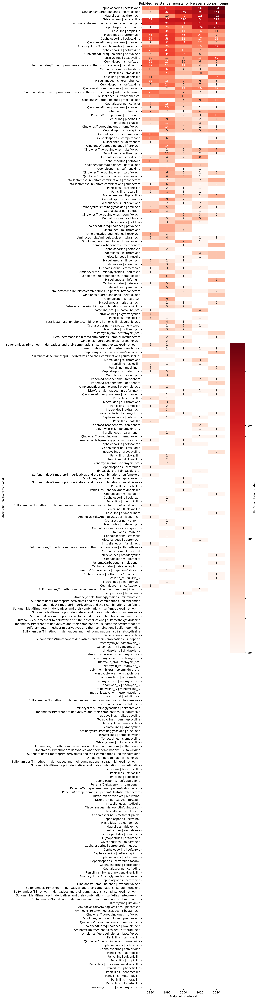

In [31]:
pathogen = 'Neisseria gonorrhoeae'
print(f"Sampled pathogen (log-weighted): {pathogen}")

# Plot heatmaps
df = amr_df[amr_df['pathogen'] == pathogen]
df.groupby('end_date')['count'].sum().plot(figsize=(14, 2))
plot_heatmap_for_pathogen(amr_df, pathogen, class_df=antibiotics_df, show_only_class=True, figsize=(10,10))
plot_heatmap_for_pathogen(amr_df, pathogen, class_df=antibiotics_df, show_only_class=False, figsize=(13,50))

Sampled pathogen (log-weighted): Staphylococcus aureus


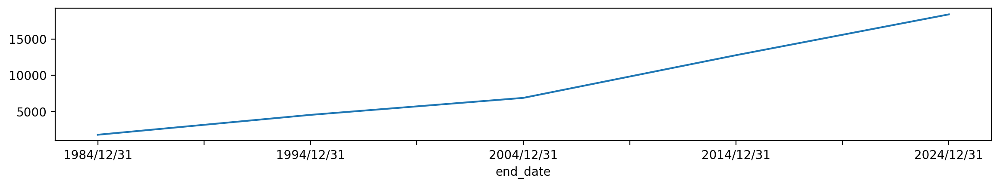

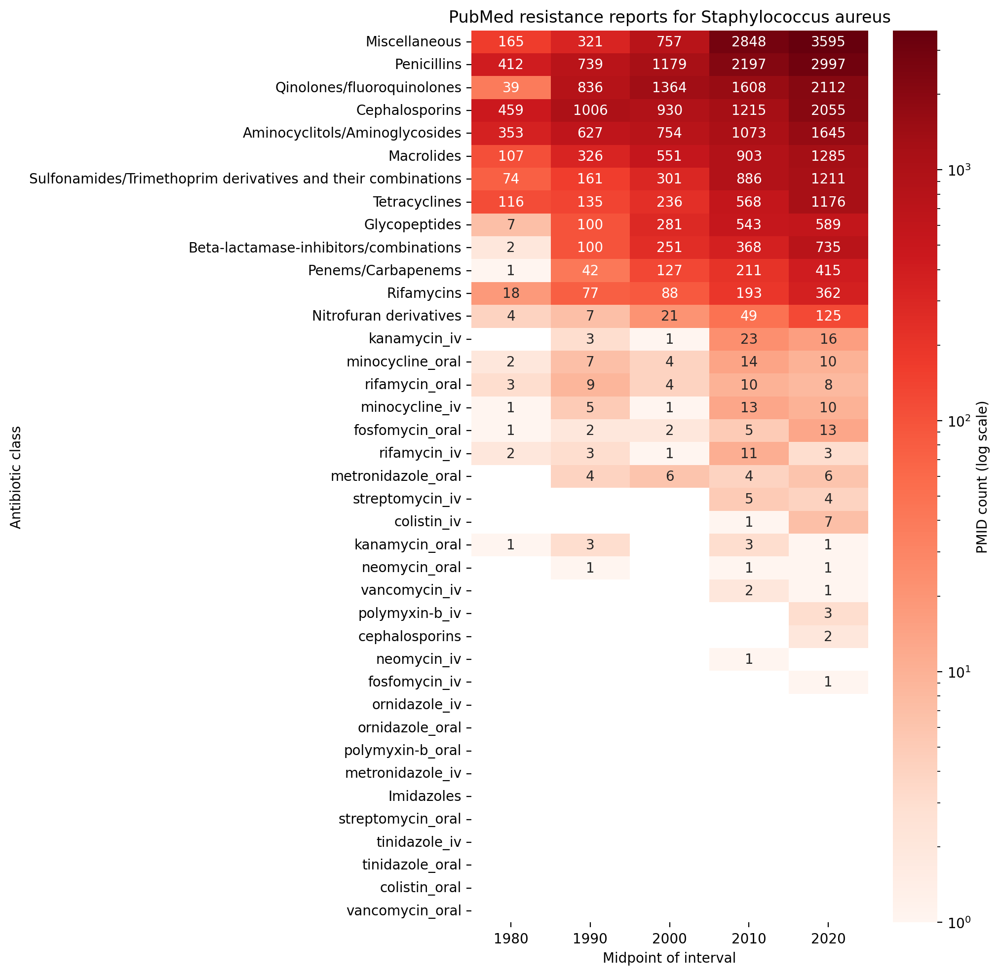

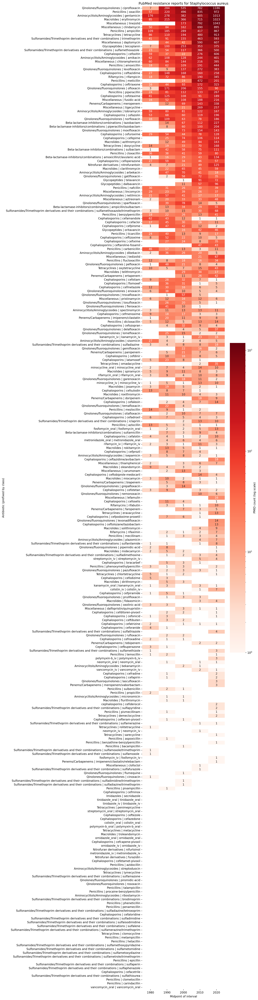

In [32]:
pathogen = 'Staphylococcus aureus'
print(f"Sampled pathogen (log-weighted): {pathogen}")

# Plot heatmaps
df = amr_df[amr_df['pathogen'] == pathogen]
df.groupby('end_date')['count'].sum().plot(figsize=(14, 2))
plot_heatmap_for_pathogen(amr_df, pathogen, class_df=antibiotics_df, show_only_class=True, figsize=(10,10))
plot_heatmap_for_pathogen(amr_df, pathogen, class_df=antibiotics_df, show_only_class=False, figsize=(13,50))

---

In [33]:
import plotly.io as pio
pio.renderers.default = "notebook"   # or "inline" / "notebook_connected"

In [34]:
import numpy as np
import pandas as pd
import umap
import plotly.express as px

def pathogen_feature_matrix(df):
    """
    Build a normalised feature matrix where each pathogen is represented as a vector
    of log-scaled counts per (antibiotic, start_date).
    """
    pivot = df.pivot_table(
        index="pathogen",
        columns=["antibiotic", "start_date"],
        values="count",
        aggfunc="sum",
        fill_value=0
    )
    pivot.columns = [f"{antibiotic}_{start}" for antibiotic, start in pivot.columns]
    pivot = np.log1p(pivot)
    pivot = pivot.div(pivot.max(axis=1), axis=0).fillna(0)
    return pivot, pivot.to_numpy()


def plot_pathogen_umap(df, n_neighbors=15, min_dist=0.1, metric="cosine"):
    """
    Create a UMAP plot of pathogens in Plotly with:
      - Square aspect ratio
      - White background
      - No axes/ticks
      - Tooltip = pathogen name only
      - Color = genus (first part of pathogen string)
      - Size ∝ log1p(total counts)
    """
    # Build features
    pivot, feature_matrix = pathogen_feature_matrix(df)

    # Run UMAP
    reducer = umap.UMAP(n_neighbors=n_neighbors, min_dist=min_dist, metric=metric, random_state=42)
    embedding = reducer.fit_transform(feature_matrix)

    # Compute cumulative counts per pathogen
    pathogen_counts = df.groupby("pathogen")["count"].sum()
    pathogen_sizes = np.log1p(pathogen_counts.loc[pivot.index].values) * 10  # scale factor

    # Extract genus for coloring
    genera = [name.split()[0] for name in pivot.index]

    # Build plot DataFrame
    umap_df = pd.DataFrame({
        "pathogen": pivot.index,
        "genus": genera,
        "umap_x": embedding[:, 0],
        "umap_y": embedding[:, 1],
        "size": pathogen_sizes
    })

    # Plot
    fig = px.scatter(
        umap_df,
        x="umap_x",
        y="umap_y",
        size="size",
        color="genus",
        hover_name="pathogen",   # only pathogen in tooltip
        hover_data={"genus": False, "umap_x": False, "umap_y": False, "size": False},
        title=None
    )

    # Style: white background, square, no axes
    fig.update_layout(
        plot_bgcolor="white",
        paper_bgcolor="white",
        xaxis=dict(showgrid=False, zeroline=False, visible=False),
        yaxis=dict(showgrid=False, zeroline=False, visible=False),
        autosize=False,
        width=600,
        height=600
    )

    fig.update_traces(marker=dict(opacity=0.8, line=dict(width=1, color="DarkSlateGrey")))

    fig.show()
    return fig, umap_df


In [35]:
pivot, feature_matrix = pathogen_feature_matrix(amr_df)

print("Pivoted DataFrame shape:", pivot.shape)
print("Feature matrix shape:", feature_matrix.shape)

# Example: first pathogen vector
print("First pathogen:", pivot.index[0])
print("Max value in row:", feature_matrix[0].max())
print("Vector length:", len(feature_matrix[0]))
fig, umap_df = plot_pathogen_umap(amr_df)

Pivoted DataFrame shape: (39, 1285)
Feature matrix shape: (39, 1285)
First pathogen: Neisseria animaloris
Max value in row: 1.0
Vector length: 1285


In [36]:
pathogen_counts


pathogen
Neisseria animaloris                   3
Neisseria bacilliformis                1
Neisseria canis                        0
Neisseria cinerea                     13
Neisseria elongata                     0
Neisseria flava                        0
Neisseria flavescens                   8
Neisseria gonorrhoeae               6252
Neisseria lactamica                   21
Neisseria macacae                      0
Neisseria meningitidis              1041
Neisseria mucosa                       2
Neisseria perflava                    21
Neisseria sicca                       11
Neisseria subflava                    21
Neisseria weaveri                      1
Staphylococcus argenteus              28
Staphylococcus aureus              44283
Staphylococcus auricularis            31
Staphylococcus capitis               244
Staphylococcus caprae                 24
Staphylococcus cohnii                153
Staphylococcus condimenti             11
Staphylococcus epidermidis          4934
Staphyl

In [37]:
pathogen_counts = pd.DataFrame(amr_df.groupby("pathogen")["count"].sum())
pathogen_counts['log'] = np.log1p(pathogen_counts.loc[pivot.index].values)

merged = pathogen_counts.merge(
    data_df,
    left_on="pathogen",
    right_on="CanonicalSpecies",
    how="inner"     # or "left"/"right"/"outer" if you need a different join
)

import plotly.express as px

fig = px.scatter(
    merged,
    x="log",
    y="pathogenic_index",
    color="Genus",
    hover_name="CanonicalSpecies",
    size="log",
    height=600,
    width=800
)
fig.show()


---

In [38]:
def plot_venue_vector(
    df_with_vecs,
    venue_index,
    row=None,
    ax=None,
    rotation=0,
    title=None,
    use_all_dates=False,
    pathogen=None,
    antibiotic=None,
    min_num=1,
):
    """
    Plot a horizontal bar chart of venue counts from df_with_vecs['venue_vector'],
    which must be a NumPy array of counts aligned with venue_index.

    Parameters
    ----------
    df_with_vecs : pd.DataFrame
        Must contain columns ['venue_vector', 'pathogen', 'antibiotic'].
    venue_index : dict
        Mapping of venue -> index position.
    row : int, optional
        Row index to plot. If None, must specify `pathogen` and `antibiotic`.
    ax : matplotlib.axes.Axes, optional
        Axis to draw on. If None, creates a new one.
    rotation : float, default=0
        Rotation for y-axis tick labels.
    title : str, optional
        Plot title.
    use_all_dates : bool, default=False
        If True, aggregates all date ranges for given pathogen/antibiotic.
    pathogen : str, optional
        Pathogen name (used if `row` is None).
    antibiotic : str, optional
        Antibiotic name (used if `row` is None).
    min_num : int, default=1
        Minimum count threshold for a venue to appear in the plot.
    """
    import matplotlib.pyplot as plt
    import numpy as np

    # ---- Validation ----
    required_cols = {"venue_vector", "pathogen", "antibiotic"}
    missing = required_cols - set(df_with_vecs.columns)
    if missing:
        raise KeyError(f"DataFrame missing required columns: {missing}")

    if not isinstance(venue_index, dict):
        raise TypeError("venue_index must be a dictionary of venue->position.")

    if row is not None and (row < 0 or row >= len(df_with_vecs)):
        raise IndexError("Row index out of range for venue_vector plot.")

    # ---- Select row(s) ----
    if row is None:
        if pathogen is None or antibiotic is None:
            raise ValueError("Provide either `row` or both `pathogen` and `antibiotic`.")
        mask = (
            (df_with_vecs["pathogen"] == pathogen)
            & (df_with_vecs["antibiotic"] == antibiotic)
        )
        if not mask.any():
            raise ValueError(f"No rows found for {pathogen} / {antibiotic}")
        selected_rows = df_with_vecs.loc[mask]
        current_row = selected_rows.iloc[0]
    else:
        current_row = df_with_vecs.iloc[row]
        if pathogen is None:
            pathogen = current_row["pathogen"]
        if antibiotic is None:
            antibiotic = current_row["antibiotic"]
        selected_rows = df_with_vecs.iloc[[row]]

    # ---- Venue order (alphabetical) ----
    venues_sorted = sorted(venue_index.keys())
    n_venues = len(venues_sorted)

    def _ensure_array(vec):
        """Ensure vector is a NumPy array of correct length."""
        if not isinstance(vec, np.ndarray):
            vec = np.array(vec)
        if vec.size < n_venues:
            pad = np.zeros(n_venues - vec.size, dtype=vec.dtype)
            vec = np.concatenate([vec, pad])
        elif vec.size > n_venues:
            vec = vec[:n_venues]
        return vec

    # ---- Aggregate or select ----
    if use_all_dates:
        all_vecs = [_ensure_array(v) for v in selected_rows["venue_vector"]]
        vector = np.sum(all_vecs, axis=0)
    else:
        vector = _ensure_array(current_row["venue_vector"])

    # ---- Reorder vector according to alphabetical venues ----
    # Map sorted venues to their corresponding index in the original vector
    index_order = [venue_index[v] for v in venues_sorted]
    vector = vector[index_order]

    # ---- Apply min_num filter ----
    mask = vector >= min_num
    if not np.any(mask):
        raise ValueError(f"No venues meet min_num={min_num} threshold.")
    venues_filtered = np.array(venues_sorted)[mask]
    values_filtered = vector[mask]

    # ---- Plot ----
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, max(4, len(venues_filtered) * 0.35)))
    else:
        fig = ax.figure

    positions = np.arange(len(venues_filtered))
    max_value = np.max(values_filtered) if len(values_filtered) else 0
    offset = 0.02 * max_value if max_value else 0.1

    bars = ax.barh(positions, values_filtered)
    for bar, value in zip(bars, values_filtered):
        y_pos = bar.get_y() + bar.get_height() / 2
        ax.text(bar.get_width() + offset, y_pos, f"{int(value)}", va="center", ha="left", fontsize=8)

    ax.set_yticks(positions)
    ax.set_yticklabels(venues_filtered, rotation=rotation)
    ax.set_xlabel("Count")
    ax.set_ylabel("Venue")
    if title:
        ax.set_title(title)
    ax.margins(y=0.01)
    fig.tight_layout()

    return ax


In [39]:
venue_index_df = pd.read_parquet("venue_index.parquet")
venue_dict = dict(zip(venue_index_df['venue'], venue_index_df.index))

df_with_vecs = pd.read_parquet("pmids_results_venues.parquet")
df_with_vecs

,pathogen,antibiotic,start_date,end_date,pmids,count,venue_histogram,venue_vector
0,Staphylococcus argenteus,Spectinomycin,1975/01/01,1984/12/31,[],0,{},"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
1,Staphylococcus argenteus,Spectinomycin,1985/01/01,1994/12/31,[],0,{},"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
2,Staphylococcus argenteus,Spectinomycin,1995/01/01,2004/12/31,[],0,{},"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
3,Staphylococcus argenteus,Spectinomycin,2005/01/01,2014/12/31,[],0,{},"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
4,Staphylococcus argenteus,Spectinomycin,2015/01/01,2024/12/31,[],0,{},"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
...,...,...,...,...,...,...,...,...
50110,Neisseria weaveri,Trimethoprim,1975/01/01,1984/12/31,[],0,{},"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
50111,Neisseria weaveri,Trimethoprim,1985/01/01,1994/12/31,[],0,{},"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
50112,Neisseria weaveri,Trimethoprim,1995/01/01,2004/12/31,[],0,{},"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."
50113,Neisseria weaveri,Trimethoprim,2005/01/01,2014/12/31,[],0,{},"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ..."


/tmp/ipykernel_652076/139650340.py:131: UserWarning:

Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.



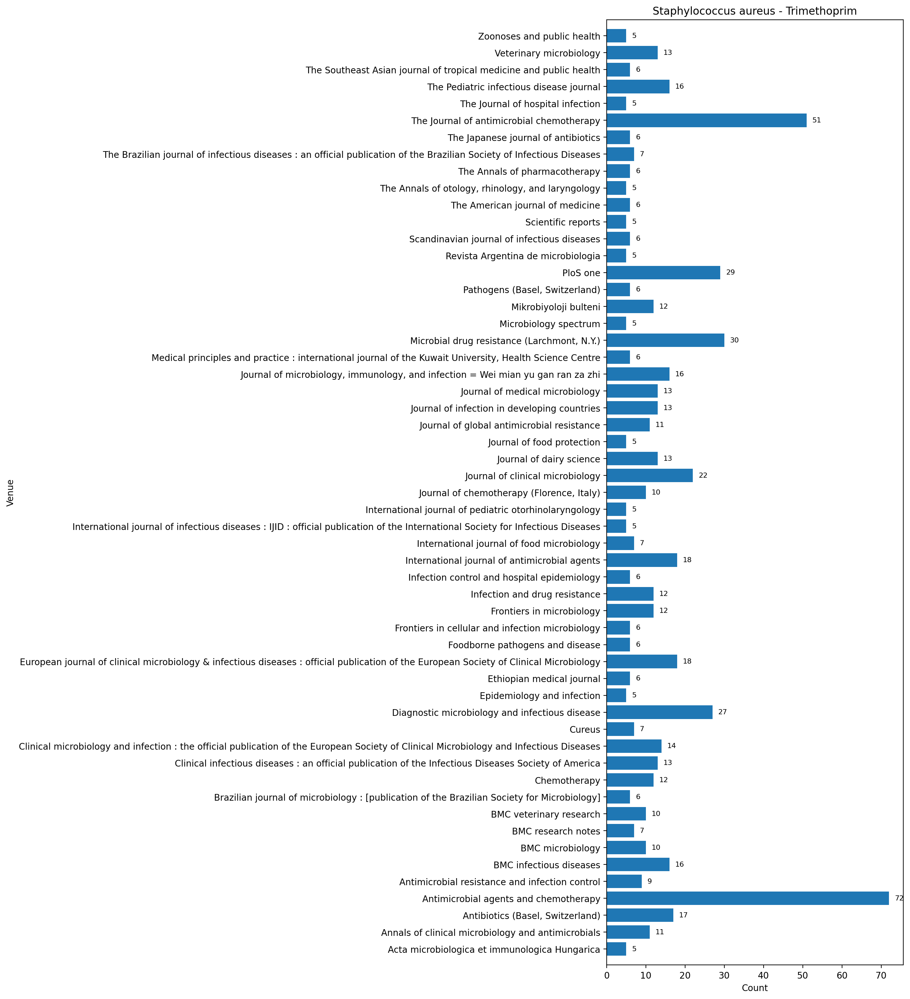

In [40]:
pathogen='Staphylococcus aureus'
antibiotic='Trimethoprim'
    
plot_venue_vector(
    df_with_vecs, venue_dict, 
    pathogen=pathogen, 
    antibiotic=antibiotic, 
    use_all_dates=True, 
    min_num=5,
    title=f'{pathogen} - {antibiotic}')
plt.show()


---